# Switch design: balancing the naive phase (tapping blocks 1–3)

**Question.** With the switch after block 3, blocks 1–3 (acoustic) and 4–9 (speech / acoustic) are analysed as two phases.
The current generator balances shift size × direction only over the **whole session**, not within blocks 1–3.

**This notebook**
1. runs the **unchanged** generator (`tapping/generate_tapping_design_table.py`) and shows the imbalance in blocks 1–3;
2. adds **one step** (`balance_phase1`): within each sentence type × role, the existing trial settings are swapped between sentences so that blocks 1–3 get a balanced third;
3. proves that **nothing else changes** (sentences, blocks, roles, trial order, exposure, session totals, all original checks);
4. plots the counterbalancing and shows the randomization is still random.

Nothing in `tapping/` is modified. Set `PROJECT_DIR` below and run all cells.

In [1]:
PROJECT_DIR = '/Users/bastugb/Desktop/tapping_detection_sentences'   # <- your project folder
JITTER_SIZES_MS = [35, 55, 75]                                       # decided 21 Nov (generator still has placeholders)
N_PARTICIPANTS = 200                                                 # simulated IDs for the across-participant checks
PHASE1_BLOCKS = [1, 2, 3]

import os, re, io, contextlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
GEN_PATH = os.path.join(PROJECT_DIR, 'tapping', 'generate_tapping_design_table.py')
pd.set_option('display.width', 160)

## 1. Load the unchanged generator
The script asks for ID and group and saves files, so it is executed here with three harmless patches:
no `os.chdir`, no input prompt, and it stops before the save cell. `JITTER_SIZES_MS` is set to [35, 55, 75].
All functions (`make_design`, `check_balance`, `make_event_table`, `check_events`) are the original ones.

In [2]:
def load_generator(path, sizes):
    src = open(path, encoding='utf-8').read()
    src = src.replace('os.chdir(PROJECT_DIR)', 'pass')
    src = src.replace('PARTICIPANT_ID, GROUP = ask_settings()', "PARTICIPANT_ID, GROUP = 'P00', 'acoustic'")
    src = re.sub(r'JITTER_SIZES_MS\s*=\s*\[[^\]]*\]', f'JITTER_SIZES_MS = {list(sizes)}', src, count=1)
    src = src[:src.find('Path(OUTPUT_DIR).mkdir')]                 # stop before saving
    ns = {}
    with contextlib.redirect_stdout(io.StringIO()):
        exec(compile(src, path, 'exec'), ns)
    plt.close('all')
    return ns

G = load_generator(GEN_PATH, JITTER_SIZES_MS)
make_design, check_balance = G['make_design'], G['check_balance']
make_event_table, check_events = G['make_event_table'], G['check_events']
print('sizes in generator:', G['JITTER_SIZES_MS'], '| blocks:', G['N_BLOCKS'], '| roles:', G['ROLES'])

sizes in generator: [35, 55, 75] | blocks: 9 | roles: ['critical_I2', 'critical_I3', 'filler', 'baseline']


## 2. The new step: `balance_phase1`
For each sentence type × role there are 18 trials: 6 land in blocks 1–3, 12 in blocks 4–9 (fixed by the generator).
The 18 **settings** (interval, size, direction, extra noise shift, …) are re-dealt among those 18 sentences:

| per type | blocks 1–3 | blocks 4–9 |
|---|---|---|
| critical I2 / I3 | each size × direction once (6); 1 of the 3 noise-carrying trials | each twice (12); 2 noise-carrying |
| filler | each size × direction once; each interval twice (1 early + 1 late); 2 of 6 noise-carrying | the rest |
| baseline | 5 unshifted + 1 noise-only | 10 + 2 |

Which setting goes to which sentence stays random (seeded from the participant ID, so it is reproducible).
**Never touched:** participant, seed, trial number (order), block, sentence type, sentence, role, exposure.

In [3]:
ID_COLS = ['participant', 'group', 'seed', 'trial', 'block', 'sentence_type', 'sentence_id', 'exposure', 'role']

def _phase1_ok(sub, role):
    if role.startswith('critical'):
        return sub.S2_with_noise.sum() == 1
    if role == 'filler':
        return ((sub.S2_interval.value_counts() == 2).all() and sub.S2_interval.nunique() == 3
                and (sub.groupby('S2_interval').S2_direction.nunique() == 2).all()
                and sub.S2_with_noise.sum() == 2)
    return True

def _pick_phase1(settings, role, rng):
    for _ in range(100_000):
        if role == 'baseline':
            none = settings.index[settings.jitter_pattern == 'none']
            ab = settings.index[settings.jitter_pattern == 'A+B']
            idx = list(rng.choice(none, 5, replace=False)) + list(rng.choice(ab, 1))
        else:                                   # one setting per size x direction
            idx = [rng.choice(g.index) for _, g in settings.groupby(['S2_size_ms', 'S2_direction'])]
        if _phase1_ok(settings.loc[idx], role):
            return idx
    raise RuntimeError(f'no balanced phase-1 set found for {role}')

def balance_phase1(df, phase1_blocks=PHASE1_BLOCKS):
    """Re-deal the trial settings within each sentence type x role so that phase 1 is balanced."""
    rng = np.random.default_rng(int(df.seed.iloc[0]) + 1)
    set_cols = [c for c in df.columns if c not in ID_COLS]
    out = df.copy()
    for (st, role), g in df.groupby(['sentence_type', 'role'], sort=True):
        settings = g[set_cols].reset_index(drop=True)
        p1_rows = g.index[g.block.isin(phase1_blocks)]
        p2_rows = g.index[~g.block.isin(phase1_blocks)]
        assert len(p1_rows) == 6 and len(p2_rows) == 12, (st, role)
        p1 = _pick_phase1(settings, role, rng)
        p2 = [i for i in settings.index if i not in p1]
        out.loc[p1_rows, set_cols] = settings.loc[rng.permutation(p1)].to_numpy()
        out.loc[p2_rows, set_cols] = settings.loc[rng.permutation(p2)].to_numpy()
    return out.astype(df.dtypes.to_dict())

## 3. One participant: original vs balanced
`check_balance` and `check_events` are the generator's own checks (whole-session balance, legal noise positions,
4 roles per sentence in 4 blocks, no back-to-back repeats, event timing).

In [4]:
PID = 'P01'
orig = make_design(PID, 'acoustic')
bal = balance_phase1(orig)

for name, d in [('original', orig), ('balanced', bal)]:
    print(f'--- {name}')
    check_balance(d)
    check_events(make_event_table(d), d)

--- original
✓ All balance checks passed
✓ Event table checks passed (6480 events; smallest silent gap 25 ms; cumulative shift -150 to +130 ms; last onset up to 13180 ms)
--- balanced
✓ All balance checks passed
✓ Event table checks passed (6480 events; smallest silent gap 25 ms; cumulative shift -150 to +130 ms; last onset up to 13180 ms)


### What did NOT change
Every identity column is identical, and within each type × role the **multiset** of settings is identical
(the session contains exactly the same trials, only dealt differently to sentences).

In [5]:
def unchanged_report(o, b):
    same_id = o[ID_COLS].equals(b[ID_COLS])
    set_cols = [c for c in o.columns if c not in ID_COLS]
    key = lambda d: (d[['sentence_type', 'role'] + set_cols].astype(str)
                     .apply(tuple, axis=1).sort_values().tolist())
    same_multiset = key(o) == key(b)
    s2 = ['S2_interval', 'S2_size_ms', 'S2_direction']
    moved = (o[s2].astype(str) != b[s2].astype(str)).any(axis=1).mean()
    return same_id, same_multiset, moved

same_id, same_ms, moved = unchanged_report(orig, bal)
print('identity columns (order, blocks, sentences, roles, exposure) identical:', same_id)
print('same trial settings per type x role (session totals identical):      ', same_ms)
print(f'share of trials whose S2 shift setting moved to another sentence:      {moved:.0%}')

# the same holds for every simulated participant
rows = []
for k in range(1, N_PARTICIPANTS + 1):
    o = make_design(f'P{k:02d}', 'acoustic'); b = balance_phase1(o)
    with contextlib.redirect_stdout(io.StringIO()):
        check_balance(b); check_events(make_event_table(b), b)
    rows.append(unchanged_report(o, b))
r = pd.DataFrame(rows, columns=['identity_same', 'settings_same', 'moved'])
print(f'\n{N_PARTICIPANTS} IDs: all original checks pass; identity identical in {r.identity_same.mean():.0%}, '
      f'session totals identical in {r.settings_same.mean():.0%}; settings moved: {r.moved.mean():.0%} on average')

identity columns (order, blocks, sentences, roles, exposure) identical: True
same trial settings per type x role (session totals identical):       True
share of trials whose S2 shift setting moved to another sentence:      63%

200 IDs: all original checks pass; identity identical in 100%, session totals identical in 100%; settings moved: 65% on average


## 4. Counterbalancing in blocks 1–3
Critical trials, count per size × direction in blocks 1–3, for each type × critical interval (the cells of the
structure test). Target after balancing: **1 in every cell**.

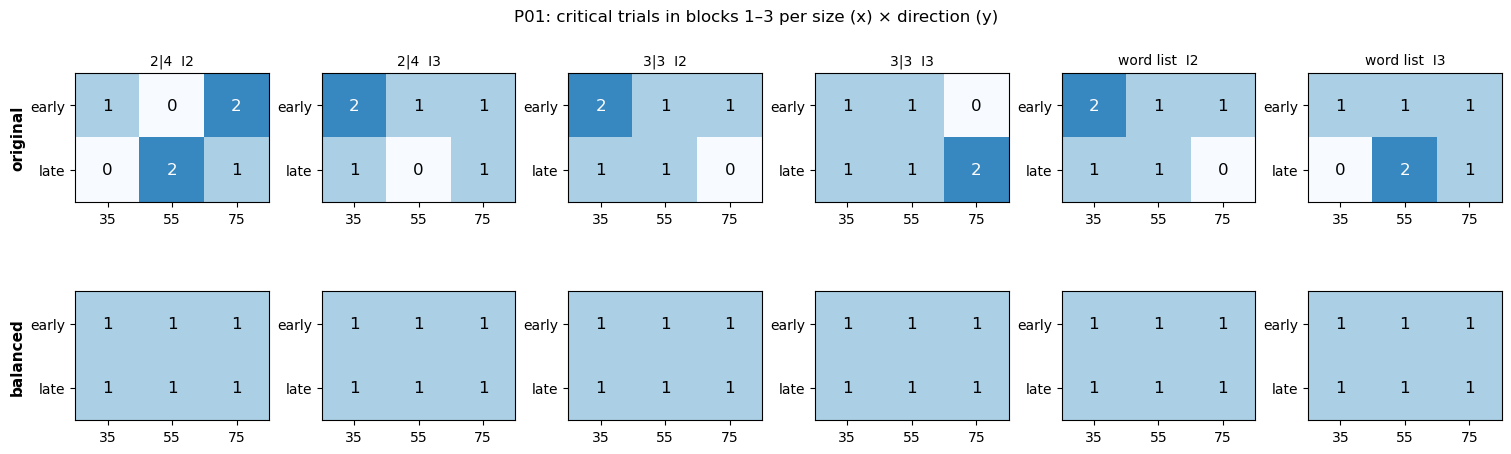

In [6]:
COMBOS = [(s, d) for s in JITTER_SIZES_MS for d in ('early', 'late')]
CELLS = [(st, iv) for st in ['2|4', '3|3', 'word list'] for iv in ['I2', 'I3']]

def phase1_counts(d):
    c = d[d.block.isin(PHASE1_BLOCKS) & d.S2_critical]
    t = c.groupby(['sentence_type', 'S2_interval', 'S2_size_ms', 'S2_direction']).size()
    return np.array([[[t.get((st, iv, s, dr), 0) for s in JITTER_SIZES_MS] for dr in ('early', 'late')]
                     for st, iv in CELLS])

fig, axes = plt.subplots(2, 6, figsize=(15, 4.6), constrained_layout=True)
for row, (name, d) in enumerate([('original', orig), ('balanced', bal)]):
    m = phase1_counts(d)
    for j, (st, iv) in enumerate(CELLS):
        ax = axes[row, j]
        ax.imshow(m[j], vmin=0, vmax=3, cmap='Blues')
        for (a, bb), v in np.ndenumerate(m[j]):
            ax.text(bb, a, v, ha='center', va='center', color='white' if v >= 2 else 'black', fontsize=12)
        ax.set_xticks(range(3), JITTER_SIZES_MS); ax.set_yticks(range(2), ['early', 'late'])
        ax.set_title(f'{st}  {iv}' if row == 0 else '', fontsize=10)
        if j == 0: ax.set_ylabel(name, fontsize=11, fontweight='bold')
fig.suptitle(f'{PID}: critical trials in blocks 1–3 per size (x) × direction (y)', fontsize=12)
plt.show()

### Across participants
For every simulated ID and every type × critical interval × size × direction cell: how many trials fall in blocks 1–3?
Original: anything from 0 to 3 (0 = the person has **no** naive trial in that cell). Balanced: always exactly 1.

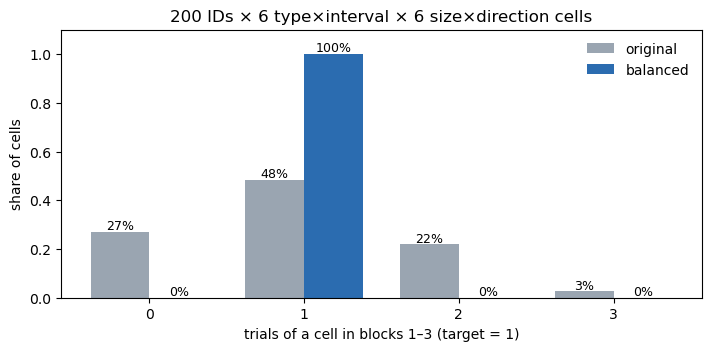

In [7]:
o_all, b_all = [], []
for k in range(1, N_PARTICIPANTS + 1):
    o = make_design(f'P{k:02d}', 'acoustic')
    o_all.append(phase1_counts(o).ravel()); b_all.append(phase1_counts(balance_phase1(o)).ravel())
o_all, b_all = np.concatenate(o_all), np.concatenate(b_all)

fig, ax = plt.subplots(figsize=(7, 3.4), constrained_layout=True)
w = 0.38
for off, data, lab, col in [(-w/2, o_all, 'original', '#9aa5b1'), (w/2, b_all, 'balanced', '#2b6cb0')]:
    share = [(data == v).mean() for v in range(4)]
    ax.bar(np.arange(4) + off, share, w, label=lab, color=col)
    for v, s in enumerate(share):
        ax.text(v + off, s + 0.01, f'{s:.0%}', ha='center', fontsize=9)
ax.set_xticks(range(4)); ax.set_xlabel('trials of a cell in blocks 1–3 (target = 1)')
ax.set_ylabel('share of cells'); ax.set_ylim(0, 1.1); ax.legend(frameon=False)
ax.set_title(f'{N_PARTICIPANTS} IDs × 6 type×interval × 6 size×direction cells')
plt.show()

### Fillers, baselines and noise shifts in blocks 1–3 (balanced design, one participant)

In [8]:
p1 = bal[bal.block.isin(PHASE1_BLOCKS)]
print('Fillers: size × direction per type (target 1 each)')
f = p1[p1.role == 'filler']
print(pd.crosstab(f.sentence_type, [f.S2_size_ms.astype(int), f.S2_direction]), '\n')
print('Fillers: interval × direction per type (target 1 each)')
print(pd.crosstab(f.sentence_type, [f.S2_interval, f.S2_direction]), '\n')
print('Baseline patterns per type (target none 5, A+B 1)')
bb = p1[p1.role == 'baseline']; print(pd.crosstab(bb.sentence_type, bb.jitter_pattern), '\n')
print('Trials with an extra noise shift, phase 1 vs 2 (per type; target 1/3 : 2/3)')
nz = bal[bal.n_jitters == 2].assign(phase=lambda d: np.where(d.block.isin(PHASE1_BLOCKS), 'blocks 1-3', 'blocks 4-9'))
print(pd.crosstab([nz.sentence_type, nz.role], nz.phase))

Fillers: size × direction per type (target 1 each)
S2_size_ms       35         55         75     
S2_direction  early late early late early late
sentence_type                                 
2|4               1    1     1    1     1    1
3|3               1    1     1    1     1    1
word list         1    1     1    1     1    1 

Fillers: interval × direction per type (target 1 each)
S2_interval      I1         I4         I5     
S2_direction  early late early late early late
sentence_type                                 
2|4               1    1     1    1     1    1
3|3               1    1     1    1     1    1
word list         1    1     1    1     1    1 

Baseline patterns per type (target none 5, A+B 1)
jitter_pattern  A+B  none
sentence_type            
2|4               1     5
3|3               1     5
word list         1     5 

Trials with an extra noise shift, phase 1 vs 2 (per type; target 1/3 : 2/3)
phase                      blocks 1-3  blocks 4-9
sentence_type role

### Blocks 4–9 and the whole session
Because the whole session is unchanged, blocks 4–9 automatically get each size × direction **twice** per type × critical interval.

In [9]:
c = bal[bal.S2_critical].assign(phase=lambda d: np.where(d.block.isin(PHASE1_BLOCKS), 'blocks 1-3', 'blocks 4-9'))
print(pd.crosstab([c.sentence_type, c.S2_interval, c.phase], [c.S2_size_ms.astype(int), c.S2_direction]))

S2_size_ms                              35         55         75     
S2_direction                         early late early late early late
sentence_type S2_interval phase                                      
2|4           I2          blocks 1-3     1    1     1    1     1    1
                          blocks 4-9     2    2     2    2     2    2
              I3          blocks 1-3     1    1     1    1     1    1
                          blocks 4-9     2    2     2    2     2    2
3|3           I2          blocks 1-3     1    1     1    1     1    1
                          blocks 4-9     2    2     2    2     2    2
              I3          blocks 1-3     1    1     1    1     1    1
                          blocks 4-9     2    2     2    2     2    2
word list     I2          blocks 1-3     1    1     1    1     1    1
                          blocks 4-9     2    2     2    2     2    2
              I3          blocks 1-3     1    1     1    1     1    1
                    

## 5. Is it still random?
Balancing fixes **how many** of each setting are in blocks 1–3, not **which sentence** gets it.
Across simulated IDs, every sentence should get every size × direction about equally often (1/6 ≈ 17 %) and be
equally likely to sit in blocks 1–3 with any setting. Shown for critical I2; the other roles behave the same.

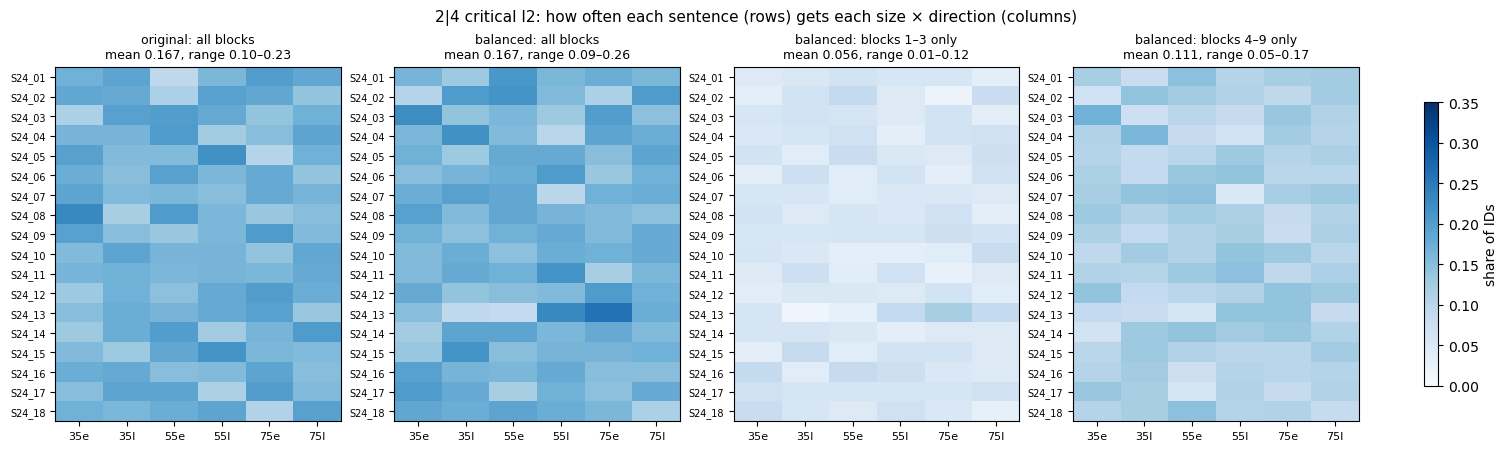

expected: all blocks 1/6 = 0.167; blocks 1–3 1/3 × 1/6 = 0.056; blocks 4–9 2/3 × 1/6 = 0.111


In [10]:
def sentence_combo_freq(designs, st, role):
    m = np.zeros((18, 6))
    for d in designs:
        g = d[(d.sentence_type == st) & (d.role == role)]
        for t in g.itertuples():
            m[int(t.sentence_id[-2:]) - 1, COMBOS.index((t.S2_size_ms, t.S2_direction))] += 1
    return m / len(designs)

designs_o = [make_design(f'P{k:02d}', 'acoustic') for k in range(1, N_PARTICIPANTS + 1)]
designs_b = [balance_phase1(d) for d in designs_o]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.4), constrained_layout=True)
panels = [('original: all blocks', designs_o, None), ('balanced: all blocks', designs_b, None),
          ('balanced: blocks 1–3 only', designs_b, True), ('balanced: blocks 4–9 only', designs_b, False)]
for ax, (title, ds, ph1) in zip(axes, panels):
    if ph1 is None:
        sel = ds
    else:
        sel = [d[d.block.isin(PHASE1_BLOCKS) == ph1] for d in ds]
    m = sentence_combo_freq(sel, '2|4', 'critical_I2')
    im = ax.imshow(m, cmap='Blues', vmin=0, vmax=0.35, aspect='auto')
    ax.set_xticks(range(6), [f'{s}{d[0]}' for s, d in COMBOS], fontsize=8)
    ax.set_yticks(range(18), [f'S24_{i:02d}' for i in range(1, 19)], fontsize=7)
    ax.set_title(f'{title}\nmean {m.mean():.3f}, range {m.min():.2f}–{m.max():.2f}', fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label='share of IDs')
fig.suptitle('2|4 critical I2: how often each sentence (rows) gets each size × direction (columns)', fontsize=11)
plt.show()
print('expected: all blocks 1/6 = 0.167; blocks 1–3 1/3 × 1/6 = 0.056; blocks 4–9 2/3 × 1/6 = 0.111')

### Within blocks 1–3
Balance is guaranteed over blocks 1–3 together, not within each single block (as in the original design, where it is
guaranteed over all 9 blocks only). Per-block counts for one participant, critical trials, all types:

In [11]:
c1 = bal[bal.block.isin(PHASE1_BLOCKS) & bal.S2_critical]
print(pd.crosstab(c1.block, [c1.S2_size_ms.astype(int), c1.S2_direction], margins=True))

S2_size_ms      35         55         75      All
S2_direction early late early late early late    
block                                            
1                2    2     3    2     2    1  12
2                3    3     0    2     2    2  12
3                1    1     3    2     2    3  12
All              6    6     6    6     6    6  36


## Conclusion
- Same sentences, blocks, roles, trial order and exposure; the same set of trials per session; all original checks pass.
- Blocks 1–3 now contain each size × direction exactly once per type × critical interval (original: 0–3 at random),
  balanced fillers and baselines, and 1/3 of the noise shifts; blocks 4–9 contain exactly twice that.
- Which sentence gets which setting is still random and reproducible from the participant ID.